In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats
import torch

from utils import block_diag

In [2]:
def func(r, k):
    return r*np.cos(1*r)*scipy.special.jv(0, k*r)

In [3]:
nk = 512
nr = 512

In [4]:
r = np.linspace(0, 3*np.pi+np.pi/2, nr) 
k = np.linspace(0, 30, nk)

In [5]:
vals = np.zeros(nk)

for i in range(nk):
    integral = scipy.integrate.quad(func, r[0], r[-1], args = (k[i],), limit = 1000)
    vals[i] = integral[0]


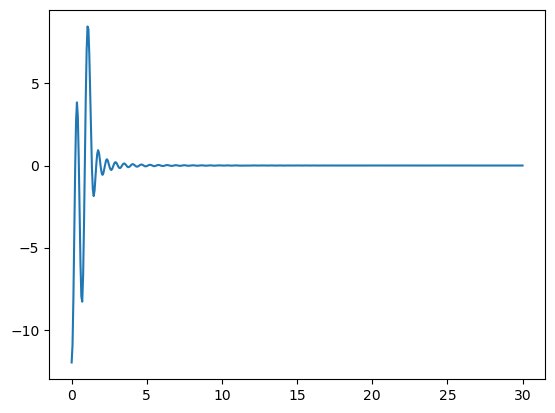

In [6]:
plt.plot(k, vals)

In [7]:
def rejection_sample(func, a, b, N):
    """
    Rejection sampling for a function func over the interval [a, b]
    """
    x = np.linspace(a, b, N)
    y = func(x)
    y_max = np.max(y)
    
    samples = []
    while len(samples) < N:
        x_sample = np.random.uniform(a, b)
        y_sample = np.random.uniform(0, y_max)
        if y_sample < func(x_sample):
            samples.append(x_sample)
    
    return np.array(samples)

In [8]:
cos_abs_integral_interp = scipy.interpolate.interp1d(k, np.abs(vals))
cos_integral_interp = scipy.interpolate.interp1d(k, vals)

In [9]:
N = 512

In [10]:
rejection_samples = rejection_sample(cos_abs_integral_interp, k[0], k[-1], N)

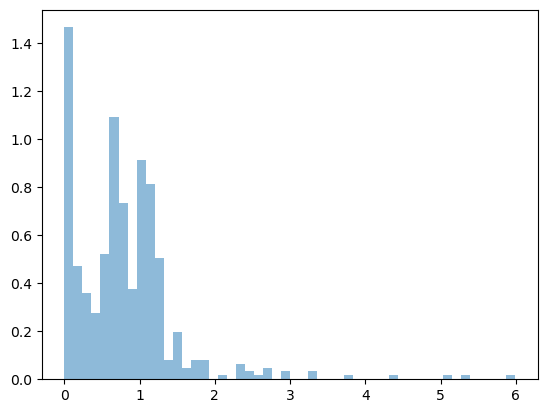

In [11]:
plt.hist(rejection_samples, bins=50, density=True, alpha=0.5, label='Rejection Samples');

In [ ]:
theta = np.linspace(0, np.pi, N)

alpha = cos_integral_interp(rejection_samples)

p0 = np.emath.sqrt(np.sign(alpha))
keys = np.argsort(p0.real)
# rejection_samples = rejection_samples[keys]

# p0 = p0[keys]
lx = rejection_samples*np.cos(theta)
ly = rejection_samples*np.sin(theta)

# lx = np.random.normal(N)
# ly = np.random.normal(N)


(np.float64(-4.3420072298388686),
 np.float64(4.602946691163033),
 np.float64(-0.26435136210509935),
 np.float64(5.551378604207086))

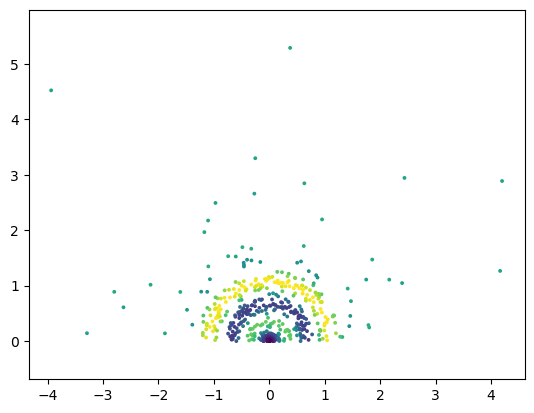

In [13]:
plt.scatter(lx, ly, c = alpha, s = 3)
plt.axis("equal")

In [14]:
a = 20
x = np.linspace(-a, a, 100)
y = np.linspace(-a, a, 100)
X, Y = np.meshgrid(x, y)
xx = X.flatten()
yy = Y.flatten()

s = np.sum((p0[None])**2*np.cos(lx[None]*xx[:,None] + ly[None]*yy[:,None]), axis = -1)
s = np.real(s)

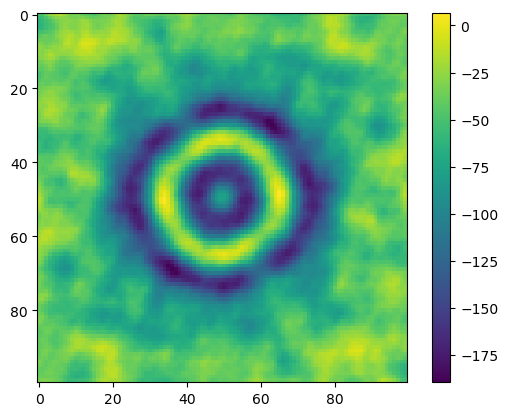

In [15]:
plt.imshow(s.reshape(100,100))
plt.colorbar()

In [16]:
Sx = block_diag(lx[:len(lx)//2])
Sy = block_diag(ly[:len(ly)//2])

In [17]:
mask = alpha > 0 
# plt.plot(rejection_samples[mask], alpha[mask],'o', color = 'red', alpha = 0.5)


l_plusx = lx[mask]
l_plusy = ly[mask]
N = len(l_plusx)*2
l_minusx = lx[~mask]
l_minusy = ly[~mask]


print(l_plusx.shape, l_plusy.shape, N)
u = (torch.rand((N, N)).to(torch.float32) - 0.5)*2 # random
Gr = (u - u.T) # skew symmetric
R = torch.matrix_exp(Gr) # orthogonal, s = 1

p0 = R.T@torch.ones((N)).to(torch.float32)

(218,) (218,) 436


In [18]:
Sxplus = block_diag(l_plusx)
Syplus = block_diag(l_plusy)
Sxminus = block_diag(l_minusx)
Syminus = block_diag(l_minusy)

In [19]:
torch.save(Sxplus, "sigma_A.pt")
torch.save(Syplus, "sigma_B.pt")
torch.save(Gr, "Gr.pt")
torch.save(p0, "p0.pt")

In [20]:
Gr.shape, Sxplus.shape, Syplus.shape

(torch.Size([436, 436]), torch.Size([436, 436]), torch.Size([436, 436]))

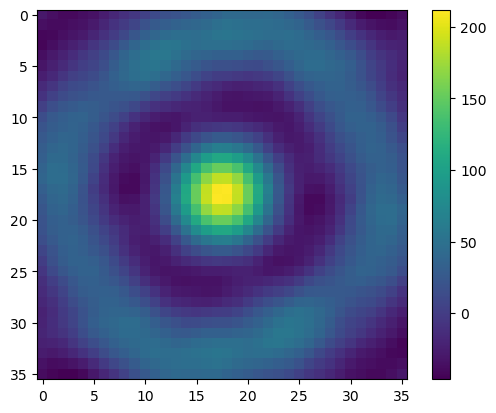

In [21]:
s = np.sum(np.cos(l_plusx[None]*xx[:,None] + l_plusy[None]*yy[:,None]), axis = -1)
s = np.real(s)
plt.imshow(s.reshape(100,100)[32:-32, 32:-32], origin="upper")
plt.colorbar()